# k-Nearest Neighbor Klassifikator

Folgendes Diagram zeigt 2D Merkmalvektoren der Klassen "Zahlen" und "Buchstaben" in Form von Zahlen (1-5) und Buchstaben (a-f)


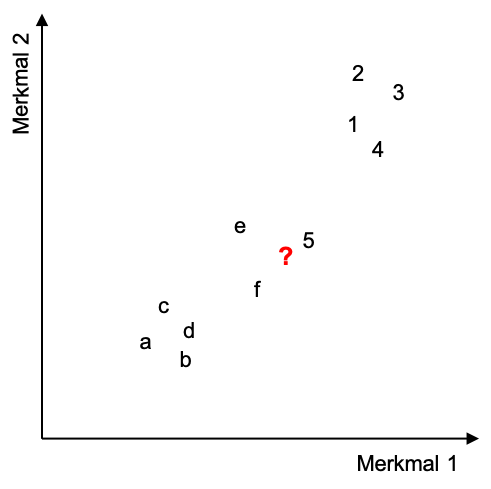

Als Distanzmaß wird der Euklidabstand verwendet.

a) Welche Klasse wird <font color='red'>?</font> bei einem 1-NN Klassifikator zugeweisen?

b) Welche Klasse wird <font color='red'>?</font> bei einem 3-NN Klassifikator zugeweisen?

c) Geben Sie an, wie sich im Falle des 3-NN Klassifikators eine Rückweisung implementieren lässt? Welchen Wert hätte <font color='red'>?</font> in diesem Fall? 

d) Beim kNN Klassifikator müssen die gesamten Trainingsdaten im Speicher gehalten werden. Zur Klassifikation müssen Distanzen für alle Trainingsbeispiele berechnet werden. <br>
  > d1) Wie könnte dieses "Effizienzproblem" gelöst werden? <br>
  > d2) Welche Nachteile hat die Methode aus d1? <br>

a) Klasse Zahlen

b) Klasse Buchstaben

c.I) Fall: 2 Klassen, dann ist eine Rückweisung nicht sinnvoll, denn eine Kombination aus 3 Nachbarn mit 2 Klassen wird immmer eine Mehrheit ergeben.

Daher hätte ? in diesem Fall trotzdem die Klasse Buchstaben.


c.II) Fall: 3 Klassen oder mehr.

Beispiel: Klassen J, K, L

Es müssen mindestens zwei Nachbarn zustimmen, sonst wird der Wert NIL zurückgegeben.

II.1] Nachbarn (K, J, L) => NIL

II.2] Nachbarn (J, L, J) => J

und so weiter


### d (TODO)


# Implementieren des kNN Klassifikators in Python

Implementieren Sie eine Klasse MyKNN, die einen kNN Klassifikator definieren soll. Als Abstandsmaß ist Euklid-Abstand zu implementieren. 

Verwenden Sie die Struktur wie in sklearn:
- Klassifikatoren werden als Klasse repraesentiert
- Es gibt eine fit()- und eine predict()-Methode

In [8]:
import ctypes

haneul = ctypes.CDLL("./libhaneul.so")

haneul.sort_keys.argtypes = [
    ctypes.POINTER(ctypes.c_uint32),
    ctypes.c_size_t
]

haneul.sort_keys.restype = None

UInt64Ptr = ctypes.POINTER(ctypes.c_uint64)

haneul.view_internal.argtypes = [
    ctypes.POINTER(UInt64Ptr),
    ctypes.c_size_t
]

haneul.view_internal.restype = ctypes.c_bool

In [9]:
import numpy as np
from math import sqrt

def dist(ref, inp):
    assert len(ref) == len(inp)
    agg = 0;
    for i in range(0, len(ref)):
        agg += (ref[i] - inp[i]) ** 2
    return sqrt(agg)

class MyKNN:
    def __init__(self, target_names, k=1):
        self.label_names = target_names
        self.k = k
        self.data = None
        self.labels = None
        self.keys = None
        self.transient_results = None
        
    def fit(self, data: np.ndarray, labels: np.ndarray): 
        assert len(data.shape) == 2
        assert len(labels.shape) == 1
        assert data.shape[0] == labels.shape[0]
        assert data.shape[0] > 0
        
        self.data = data
        self.labels = labels

        # used for returning values (and observing them)
        # the values live until predict() is called again
        # clone contents if you want to you want to keep them around.
        self.transient_results = np.zeros(self.data.shape[0], dtype=np.int64)
            
        # reusable container for sorting:
        self.keys = np.zeros(self.data.shape[0], dtype=np.float32)
        
    def predict(self, new_data: np.ndarray):
        # TODO(yousef): new predictions should be added to self.data, self.labels
        
        # TODO(yousef): next step, maybe you don't need to scan all data points linearly
        # if you find a better way to store said data or accept some *loss of accuracy*
        
        assert new_data.shape[0] > 0
        assert new_data[1].shape == self.data[1].shape

        if len(new_data) > len(self.transient_results):
            self.transient_results = np.resize(self.transient_results, (len(new_data),))
            
        
        ref = self.data
        for res_at, vec in enumerate(new_data):
            haneul.distance_loop(keys, )
            
            for i in range(0, len(ref)):
                self.keys[i] = dist(ref[i], vec)

            # reinterpret floats as u32 (without copying)
            keys_u32 = self.keys.view(np.uint32)
            
            keys_ptr = keys_u32.ctypes.data_as(ctypes.POINTER(ctypes.c_uint32))
            len_keys = len(keys_u32) 
            haneul.sort_keys(keys_ptr, len_keys);

            # read indices without copying
            indices_view = UInt64Ptr()
            length = ctypes.c_size_t(len_keys) 
            haneul.view_internal(ctypes.byref(indices_view), length)
            indices = np.ctypeslib.as_array(indices_view, shape=(len_keys,))

            k_labels = [self.labels[i] for i in indices[:self.k+1]]
            
            counts = np.bincount(k_labels)
            max_label = np.argmax(counts)
            
            self.transient_results[res_at] = max_label

        return self.transient_results

## Testen Sie das Verfahren auf Datensätzen Ihrer Wahl, z.B. 
- Iris-data
- Digit-data
- Wine-data
von sklearn


Zunächst Training = Test

In [15]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
iris_dataset = load_iris()

X=iris_dataset['data'][:,[0,1]] # wir nehmen die ersten beiden Merkmale aus den Iris-Daten und speichern diese in der Matrix X

y=iris_dataset['target']        # Die labels, die zum Training noetig sind, werden in ein array y gespeichert.

yousef_knn = MyKNN(iris_dataset["target_names"], k=5)

print(X.dtype)
yousef_knn.fit(X,y)                    # mittels der fit-Methode, wird der Klassifikator trainiert. fit benoetigt Daten (X) und labels (y).  
                                # predict wird spaeter zur Erkennung benutzt. fit() & predict() wird in sklearn fuer alle Klassifikatoren verwendet (siehe https://scikit-learn.org/stable/tutorial/basic/tutorial.html#learning-and-predicting)

x1_min,x1_max = X[:,0].min() -1, X[:,0].max()+1    # fuer beide Merkmale werden min- und max-Werte bestimmt.  
x2_min,x2_max = X[:, 1].min() -1 , X[:,1].max()+1  

xx1,xx2 = np.meshgrid(np.arange(x1_min,x1_max,0.1), np.arange(x2_min,x2_max,0.1))  
#Aus den mix/max-Werten, werden zuerst Arrays erzeugt mittel arange. x_min ist der Start-Wert, x_max der End-Wert, die Schrittweite ist 0.1
#Daraus werden dann die Matrizen xx1 und xx2 durch meshgrid erzeugt um den moeglichen Merkmalraum zu erzeugen 

example_vecs=np.c_[xx1.ravel(), xx2.ravel()] #xx1 und xx2 werden zuerst in arrays "geflacht" mittels ravel(). 
                                                    # c_() erzeugt anschliessend aus den Daten jeweils Wertepaare, welche moeglichen Merkmalvektoren entsprechen
print(example_vecs.shape)  #2464 Vektoren

float64
(2464, 2)


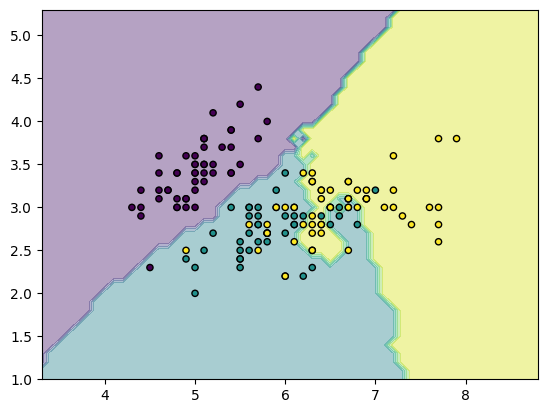

In [14]:
Z = yousef_knn.predict(example_vecs)

Z = Z.reshape(xx1.shape) #Das array Z wird in den shape von xx1,bzw xx2 gebracht 

plt.contourf(xx1,xx2,Z,alpha=0.4) #Erzeugt einen Contour-plot der Punkte xx1 und xx2 mit den erkannten labels Z

plt.scatter(X[:,0],X[:,1],c=iris_dataset.target ,s=20,edgecolor='k')  # mit diesem Befehl koennen die eigentlich Datenpunkte, mit denen der kNN-Klassifikator trainiert wurde geplottet werrden

plt.show()

## Verwenden Sie den Visualisierungscode aus dem Vorlesungs-Notebook um Ihre Implementierung zu testen.

## Bestimmen Sie die Güte Ihres Klassifikators und Testen Sie unterschiedliche Werte für k.

## Zerlegen Sie die Daten in ein Trainings- und Testset und testen Sie erneut.

## Verwenden Sie ein Validierungsset zur Bestimmung eines geeigneten Parameters k

## Verwenden Sie eine Kreuzvalidierung zur Bestimmung von k

